In [35]:
# from datasets import load_dataset

# dataset = load_dataset("Console-AI/IT-helpdesk-synthetic-tickets")

# print(dataset)

In [36]:
import pandas as pd
df = pd.read_csv('../data/processed/processed.csv')
print(df.keys())

Index(['id', 'subject', 'description', 'priority', 'category', 'createdAt',
       'requesterEmail'],
      dtype='str')


In [37]:
#want it as a dataframe for easier interpretability
# print(type(dataset))
# print(dataset.keys())


print(type(df))
# print(dataset)

# print(dataset[0])

<class 'pandas.DataFrame'>


In [38]:

#size 500x7 
print(df.shape)

(490, 7)


In [39]:
df.head()

,id,subject,description,priority,category,createdAt,requesterEmail
0,1aiu3lrqi,Hey IT! Our network printer keeps disconnecting.,Hey IT! Our network printer keeps disconnectin...,Medium,Network,2024-10-28T18:36:55.004Z,jane.doe@acme.co
1,kz5mjjpox,Re: [Acme IT] Re: Ticket #98765 - Access Issue...,This is a follow-up to your previous request #...,High,Network,2024-10-28T18:36:56.156Z,user123@acme.co
2,86eza0fwq,Software Conflict Causing App Crashes,Hey team! :wave: We're experiencing some inter...,High,Software,2024-10-28T18:36:54.644Z,user@acme.co
3,jtw509e3n,j.doe@acme.co Google Calendar Setup Assistance,We need to set up a new Google Calendar for te...,Medium,Software,2024-10-28T18:36:54.524Z,j.doe@acme.co
4,tso616mbn,Software Access: Asana Project for Jordan Smith,Jordan Smith is part of the Project Management...,Medium,Software,2024-10-28T18:36:54.816Z,jordan.smith@acme.co


In [40]:
# shows first few records of dataframe
# df.head()

# for size of table
# df.shape

# for names of each column
# df.columns

# generic info
# df.info()

# number of empties boxes in records?
# df.isnull().sum()

# number of each category
df["category"].value_counts()

# number of each priority
# df["priority"].value_counts()

# picks 10 random records and shows the corresponding fields
# df[["subject", "description", "category"]].sample(10)



category
Software         231
Account           71
Network           68
Security          42
Communication     24
Hardware          22
RemoteWork        20
Training          12
Name: count, dtype: int64

In [41]:
df[["subject", "description", "category"]].sample(
    10,
    random_state=42
)

df["subject_length"]=df["subject"].str.split().str.len()
df["description_length"]=df["description"].str.split().str.len()

df[["subject_length", "description_length"]].describe()

,subject_length,description_length
count,490.000000,490.000000
mean,6.573469,59.924490
std,2.572409,58.655457
min,3.000000,3.000000
25%,5.000000,28.000000
50%,6.000000,45.000000
75%,7.000000,68.000000
max,23.000000,606.000000


In [42]:
print("Duplicate subjects:")
print(df["subject"].duplicated().sum())

print("Duplicate descriptions:")
print(df["description"].duplicated().sum())

print("Duplicate subject + description:")
print(
    df.duplicated(
        subset=["subject", "description"]
    ).sum()
)

Duplicate subjects:
11
Duplicate descriptions:
3
Duplicate subject + description:
0


In [43]:
# Metrics to compare subject length Vs description length
# Large differences in lengths means it's likely favourable to keep both

# df.groupby("category")[
#     ["subject_length", "description_length"]
# ].mean().round(2)

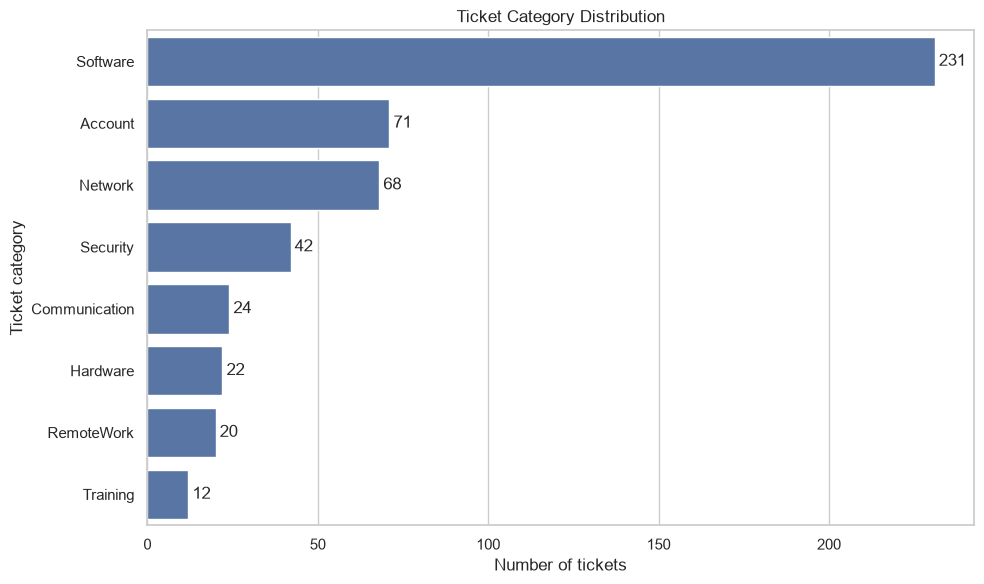

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10,6))

ax=sns.countplot(
      data=df,
      y = "category",
      order=df["category"].value_counts().index
)

ax.bar_label(ax.containers[0], padding=3)

plt.xlabel("Number of tickets")
plt.ylabel("Ticket category")
plt.title("Ticket Category Distribution")

plt.tight_layout()
plt.show()

So Tickets falling under the "Software" category take the majority of the tickeets in this dataset. We need to approach the dataset carefully so that models won't just predict "Software" and get away with a seemingly high prediction accuracy.

In [45]:
# This will the be text fed into the prediction algorithm

df["text"] = (
    df["subject"].str.strip() + " " + df["description"].str.strip()
)

df.head()

,id,subject,description,priority,category,createdAt,requesterEmail,subject_length,description_length,text
0,1aiu3lrqi,Hey IT! Our network printer keeps disconnecting.,Hey IT! Our network printer keeps disconnectin...,Medium,Network,2024-10-28T18:36:55.004Z,jane.doe@acme.co,7,43,Hey IT! Our network printer keeps disconnectin...
1,kz5mjjpox,Re: [Acme IT] Re: Ticket #98765 - Access Issue...,This is a follow-up to your previous request #...,High,Network,2024-10-28T18:36:56.156Z,user123@acme.co,13,88,Re: [Acme IT] Re: Ticket #98765 - Access Issue...
2,86eza0fwq,Software Conflict Causing App Crashes,Hey team! :wave: We're experiencing some inter...,High,Software,2024-10-28T18:36:54.644Z,user@acme.co,5,40,Software Conflict Causing App Crashes Hey team...
3,jtw509e3n,j.doe@acme.co Google Calendar Setup Assistance,We need to set up a new Google Calendar for te...,Medium,Software,2024-10-28T18:36:54.524Z,j.doe@acme.co,5,30,j.doe@acme.co Google Calendar Setup Assistance...
4,tso616mbn,Software Access: Asana Project for Jordan Smith,Jordan Smith is part of the Project Management...,Medium,Software,2024-10-28T18:36:54.816Z,jordan.smith@acme.co,7,22,Software Access: Asana Project for Jordan Smit...


In [46]:
for category in df["category"].unique():

    print("\n" + "=" * 60)
    print(category)
    print("=" * 60)

    examples = df[df["category"] == category][
        ["subject", "description"]
    ].head(3)

    for _, row in examples.iterrows():
        print("\nSUBJECT:")
        print(row["subject"])

        print("\nDESCRIPTION:")
        print(row["description"])


Network

SUBJECT:
Hey IT! Our network printer keeps disconnecting.

DESCRIPTION:
Hey IT! Our network printer keeps disconnecting intermittently and requires manual IP reconfiguration each time. It's becoming quite a hassle, especially during busy hours. A few folks in the office have mentioned they're experiencing the same issue. Could you look into this? Thanks!

SUBJECT:
Re: [Acme IT] Re: Ticket #98765 - Access Issue with Shared Network Drive

DESCRIPTION:
This is a follow-up to your previous request #98765 "Access Issue with Shared Network Drive"

Hello!

I'm having trouble accessing the shared network drive. It used to work fine, but now I'm getting permission errors that seem quite complex. I believe it might require a detailed audit and manual adjustment to resolve.

Here's a screenshot of the error message (https://acme.co/share/error-screenshot) . I've tried basic troubleshooting steps like checking my network connection and restarting my computer.

Thanks, and please let me k

In [ ]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["category"]

# Choose a 70/15/15 split for Train test and val splits
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state= 234
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state= 234
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))


Training: 343
Validation: 73
Test: 74

TRAIN
category
Software         162
Account           50
Network           48
Security          29
Communication     17
Hardware          15
RemoteWork        14
Training           8
Name: count, dtype: int64

VALIDATION
category
Software         34
Account          10
Network          10
Security          6
Communication     4
Hardware          4
RemoteWork        3
Training          2
Name: count, dtype: int64

TEST
category
Software         35
Account          11
Network          10
Security          7
RemoteWork        3
Communication     3
Hardware          3
Training          2
Name: count, dtype: int64


In [64]:
# Make a baseline model, that picks the most common category
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_preds = dummy.predict(X_val)

print("Accuracy:", accuracy_score(y_val, dummy_preds))
print("Weighted F1:", f1_score(y_val, dummy_preds, average="weighted"))
print("Macro F1:", f1_score(y_val, dummy_preds, average="macro"))


Accuracy: 0.4657534246575342
Weighted F1: 0.2959928306234797
Macro F1: 0.0794392523364486


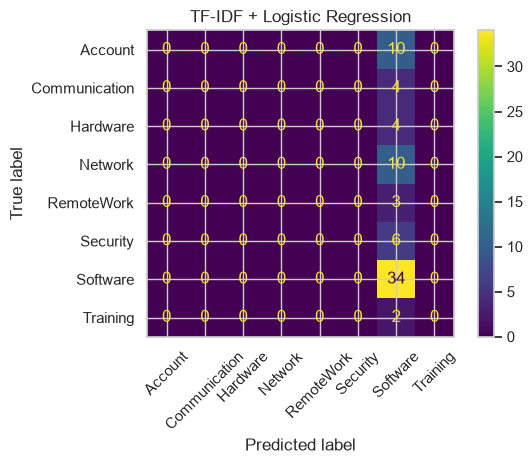

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    dummy_preds,
    xticks_rotation=45
)

plt.title("Dummy Baseline Model")
plt.tight_layout()
plt.show()

In [ ]:
# model that extracts important words and bigrams
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1,2),
    min_df=2
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)

print(X_train_tfidf.shape)
print(X_val_tfidf.shape)

# print(X_train_tfidf[0])
# print(X_val_tfidf[0])

feature_names = vectorizer.get_feature_names_out()

print(feature_names[:50])
print("Number of features:", len(feature_names))



(343, 3460)
(73, 3460)
['00' '00 00' '00 000' '00 07' '00 am' '00 cst' '00 pst' '00 request'
 '00 review' '000' '000 05' '000 07' '01' '0199' '05' '05 00' '06t11'
 '06t11 00' '06t11 30' '07' '07 00' '07 15t09' '08' '09' '09 00' '09 15'
 '10' '10 00' '10 15' '10 2023' '10 30' '10 45' '10001' '101' '101 faq'
 '11' '12' '123' '123 4567' '123 innovation' '1234' '1234 elm' '12345'
 '12345 you' '12345abcde67890fghij' '12345abcde67890fghij effective' '14'
 '14 30' '14 45' '15']
Number of features: 3460


In [58]:
# put vectors form tfidf and put into logistic
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state= 234
)

model.fit(X_train_tfidf, y_train)
val_preds = model.predict(X_val_tfidf)

In [ ]:
from sklearn.metrics import classification_report

print("Accuracy:", accuracy_score(y_val, val_preds))
print("Weighted F1:", f1_score(y_val, val_preds, average="weighted"))
print("Macro F1:", f1_score(y_val, val_preds, average="macro"))

print(classification_report(y_val, val_preds))

Accuracy: 0.6027397260273972
Weighted F1: 0.5162100456621005
Macro F1: 0.2885416666666667
               precision    recall  f1-score   support

      Account       1.00      0.20      0.33        10
Communication       0.00      0.00      0.00         4
     Hardware       0.00      0.00      0.00         4
      Network       1.00      0.50      0.67        10
   RemoteWork       0.00      0.00      0.00         3
     Security       0.75      0.50      0.60         6
     Software       0.55      1.00      0.71        34
     Training       0.00      0.00      0.00         2

     accuracy                           0.60        73
    macro avg       0.41      0.28      0.29        73
 weighted avg       0.59      0.60      0.52        73



c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\andyl\Projects\Python\TicketClassifier\classifervEnv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

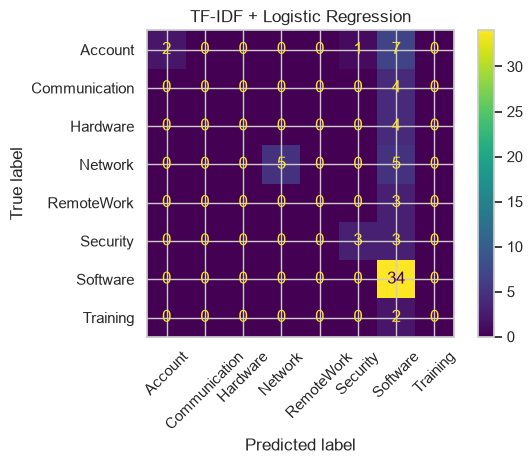

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_preds,
    xticks_rotation=45
)

plt.title("TF-IDF + Logistic Regression")
plt.tight_layout()
plt.show()

In [69]:
balanced_logistic = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=234
)

balanced_logistic.fit(X_train_tfidf, y_train)
balanced_preds = balanced_logistic.predict(X_val_tfidf)

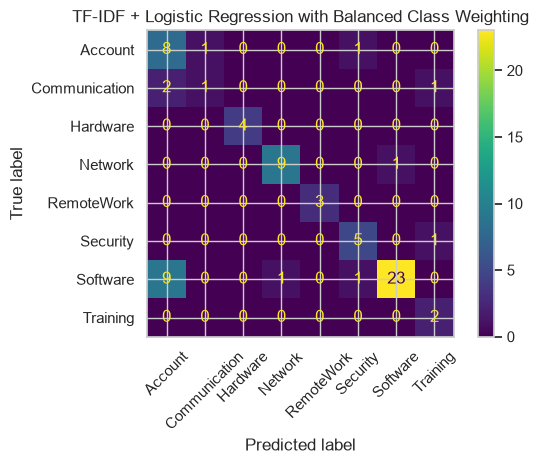

In [72]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    balanced_preds,
    xticks_rotation=45
)

plt.title("TF-IDF + Logistic Regression with Balanced Class Weighting")
plt.tight_layout()
plt.show()

In [70]:
results = []

results.append({
    "model": "Dummy Baseline",
    "accuracy": accuracy_score(y_val, dummy_preds),
    "weighted_f1": f1_score(y_val, dummy_preds, average="weighted"),
    "macro_f1": f1_score(y_val, dummy_preds, average="macro")
})

results.append({
    "model": "TF-IDF + Logistic Regression",
    "accuracy": accuracy_score(y_val, val_preds),
    "weighted_f1": f1_score(y_val, val_preds, average="weighted"),
    "macro_f1": f1_score(y_val, val_preds, average="macro")
})

results.append({
    "model": "TF-IDF + Logistic Regression with Balanced Classes",
    "accuracy": accuracy_score(y_val, balanced_preds),
    "weighted_f1": f1_score(y_val, balanced_preds, average="weighted"),
    "macro_f1": f1_score(y_val, balanced_preds, average="macro")
})


In [71]:
results_df = pd.DataFrame(results)
results_df

,model,accuracy,weighted_f1,macro_f1
0,Dummy Baseline,0.465753,0.295993,0.079439
1,TF-IDF + Logistic Regression,0.602740,0.516210,0.288542
2,TF-IDF + Logistic Regression with Balanced Cla...,0.753425,0.763902,0.751757


Comparing the TF-IDF to the baseline model we see that there's a small improvement, but after treating class weightings as more balanced all of a sudden we get some reasonable results. The confusion matrix shows a stronger leading diagonal than the prior examples. A large source of errors from the balanced model is from misassigning software tickets as account tickets, which could suggest overlap in topics between the two categories.

We could check the contents of tickets that the model misclassed as account rather than software